In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

In [2]:
df = pd.read_csv('C:\\Users\\santa\\Desktop\\Cositas de Python\\UNI\\IA\\proyectoIA\\data\\clean\\siniestralidad_clean.csv')

df.head(5)

C:\Users\santa\AppData\Local\Temp\ipykernel_21112\3145024453.py:1: DtypeWarning: Columns (0: codigo, 1: medio_reporte, 2: direccion_original, 3: direccion_norm) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('C:\\Users\\santa\\Desktop\\Cositas de Python\\UNI\\IA\\proyectoIA\\data\\clean\\siniestralidad_clean.csv')


,codigo,fecha,anio,mes,dia_semana_num,dia_semana,es_fin_semana,es_festivo,severidad,fallecido_foraneo,...,veh_motocarro,veh_automovil,veh_camioneta_campero,veh_bus,veh_carga_pesada,veh_bicicleta,direccion_original,direccion_norm,direccion_valida,direccion_con_corrupcion
0,96159,2016-01-01,2016,1,4,viernes,False,True,Solo daños,False,...,False,False,False,False,False,False,Carrera 56 Con Calle 1 A,CARRERA 56 CON CALLE 1 A,True,False
1,96161,2016-01-01,2016,1,4,viernes,False,True,Con lesionado,False,...,False,False,False,False,False,False,Carrera 94 Con Calle 4 C,CARRERA 94 CON CALLE 4 C,True,False
2,96162,2016-01-01,2016,1,4,viernes,False,True,Con lesionado,False,...,False,False,False,False,False,False,Carrera 8 A Con Calle 44,CARRERA 8 A CON CALLE 44,True,False
3,96164,2016-01-01,2016,1,4,viernes,False,True,Solo daños,False,...,False,True,False,False,False,False,Carrera 46 C Con Calle 36,CARRERA 46 C CON CALLE 36,True,False
4,96167,2016-01-01,2016,1,4,viernes,False,True,Con lesionado,False,...,NaN,NaN,NaN,NaN,NaN,NaN,Carrera 23 Con Transversal 25,CARRERA 23 CON TRANSVERSAL 25,True,False


In [3]:
veh_cols = [c for c in df.columns if c.startswith('veh_')]

# 1. Nulos por columna
nulos_col = df[veh_cols].isna().sum().to_frame('nulos')
nulos_col['pct'] = (nulos_col['nulos'] / len(df) * 100).round(2)
print(nulos_col, '\n')

# 2. ¿Son filas completamente sin dato, o NaN parciales?
n_veh = len(veh_cols)
nan_por_fila = df[veh_cols].isna().sum(axis=1)
sin_dato = nan_por_fila == n_veh          # todas las veh_* vacías
parcial = (nan_por_fila > 0) & ~sin_dato  # solo algunas vacías

print(f'Filas totales:                {len(df):,}')
print(f'Filas sin dato de vehículos:  {sin_dato.sum():,} ({sin_dato.mean():.2%})')
print(f'Filas con NaN parcial:        {parcial.sum():,} ({parcial.mean():.2%})\n')

# 3. ¿Se concentran en ciertos años? (puede delatar un cambio en el sistema de captura)
por_anio = (df.assign(sin_dato=sin_dato)
              .groupby('anio')['sin_dato']
              .agg(['sum', 'mean'])
              .rename(columns={'sum': 'filas_sin_dato', 'mean': 'proporcion'}))
por_anio['proporcion'] = (por_anio['proporcion'] * 100).round(2)
print(por_anio, '\n')

# 4. ¿Cambia la severidad entre filas con y sin dato? (si cambia, excluirlas sesga el modelo)
comparacion = (pd.crosstab(sin_dato.rename('sin_dato_veh'), df['severidad'], normalize='index') * 100).round(2)
print(comparacion)

                       nulos    pct
veh_moto               23181  18.56
veh_motocarro          23181  18.56
veh_automovil          23181  18.56
veh_camioneta_campero  23181  18.56
veh_bus                23181  18.56
veh_carga_pesada       23181  18.56
veh_bicicleta          23181  18.56 

Filas totales:                124,889
Filas sin dato de vehículos:  23,181 (18.56%)
Filas con NaN parcial:        0 (0.00%)

      filas_sin_dato  proporcion
anio                            
2016            8300       50.26
2017            2587       15.20
2018            4589       19.65
2019            4526       19.25
2020            1596       11.40
2021             565        4.85
2022             355        3.56
2023             442        8.99
2024             221        5.59 

severidad     Con fallecido  Con lesionado  Solo daños
sin_dato_veh                                          
False                  1.48          39.34       59.18
True                   8.01          32.30       59.69


In [4]:
# Imputación con bandera
veh_cols = [c for c in df.columns if c.startswith('veh_')]
df['veh_sin_dato'] = df[veh_cols].isna().all(axis=1)
df[veh_cols] = df[veh_cols].fillna(False).astype(bool)

# ¿Los fallecidos de las filas sin dato son foráneos?
print(pd.crosstab(df['veh_sin_dato'], df['fallecido_foraneo'], margins=True))

# Target binario: proporción de Grave por grupo (verifica el matiz de arriba)
df['grave'] = df['severidad'].isin(['Con lesionado', 'Con fallecido'])
print((df.groupby('veh_sin_dato')['grave'].mean() * 100).round(2))

fallecido_foraneo   False  True     All
veh_sin_dato                           
False              101451   257  101708
True                22985   196   23181
All                124436   453  124889
veh_sin_dato
False    40.82
True     40.31
Name: grave, dtype: float64


In [5]:
# Fallecidos sin dato de vehículos, por año
fall = df['severidad'] == 'Con fallecido'
print(pd.crosstab(df['anio'], [df['veh_sin_dato'], fall], 
                  rownames=['anio'], colnames=['sin_dato_veh', 'fallecido']))

sin_dato_veh  False       True       
fallecido     False True  False True 
anio                                 
2016           8105   108  8046   254
2017          14272   157  2350   237
2018          18558   207  4345   244
2019          18803   179  4313   213
2020          12213   187  1391   205
2021          10900   185   376   189
2022           9443   181   152   203
2023           4309   165   220   222
2024           3602   134   131    90


In [6]:
# Proporción de fallecidos dentro de las filas sin dato, por año
fall = df['severidad'] == 'Con fallecido'
print((df[df['veh_sin_dato']].groupby('anio')['severidad']
       .apply(lambda s: (s == 'Con fallecido').mean() * 100).round(1)), '\n')

# ¿La bandera es informativa para el target binario, por año?
print((df.groupby(['anio', 'veh_sin_dato'])['grave'].mean().unstack() * 100).round(1), '\n')

# Siniestros totales vs graves por año (¿la caída es de eventos leves?)
print(df.groupby('anio').agg(total=('grave', 'size'), graves=('grave', 'sum')))

anio
2016     3.1
2017     9.2
2018     5.3
2019     4.7
2020    12.8
2021    33.5
2022    57.2
2023    50.2
2024    40.7
Name: severidad, dtype: float64 

veh_sin_dato  False  True 
anio                      
2016           53.9   50.0
2017           42.4   48.6
2018           30.6   25.8
2019           27.7   24.5
2020           32.8   31.0
2021           38.4   51.2
2022           44.2   74.9
2023           88.3   90.0
2024           92.1   89.1 

      total  graves
anio               
2016  16513    8577
2017  17016    7379
2018  23354    6926
2019  23508    6366
2020  13996    4559
2021  11650    4549
2022   9979    4515
2023   4916    4350
2024   3957    3639


      total  graves  solo_danos  pct_grave
anio                                      
2016  16513    8577        7936       51.9
2017  17016    7379        9637       43.4
2018  23354    6926       16428       29.7
2019  23508    6366       17142       27.1
2020  13996    4559        9437       32.6
2021  11650    4549        7101       39.0
2022   9979    4515        5464       45.2
2023   4916    4350         566       88.5
2024   3957    3639         318       92.0 

Días sin ningún registro: 2


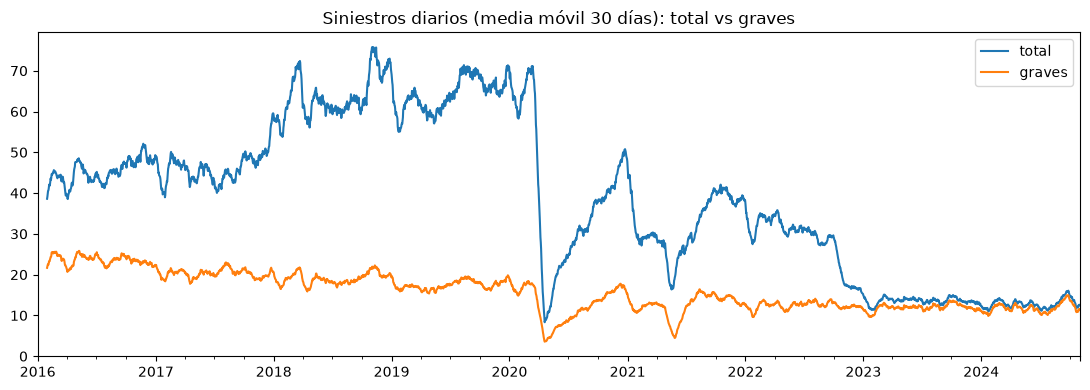


Graves por día de la semana (0 = lunes):
            mean  std
dia_semana           
0           12.6  4.0
1           12.0  3.9
2           11.8  4.2
3           12.4  3.8
4           12.4  4.4
5           12.6  4.1
6           11.8  4.2

Graves por mes:
     mean  std
mes           
1    10.4  3.4
2    12.9  3.7
3    12.7  3.1
4    11.1  4.1
5    10.1  5.2
6    12.2  3.9
7    13.3  4.3
8    13.0  4.5
9    13.9  3.9
10   13.0  3.6
11   12.7  3.5
12   11.8  3.9

Festivo vs no festivo:
es_festivo
False    12.4
True      9.9
Name: graves, dtype: float64


In [8]:
# 1. Prevalencia por año (para confirmar el split propuesto)
prev = df.groupby('anio')['grave'].agg(total='size', graves='sum')
prev['solo_danos'] = prev['total'] - prev['graves']
prev['pct_grave'] = (prev['graves'] / prev['total'] * 100).round(1)
print(prev, '\n')

# 2. Tabla agregada diaria
df['fecha'] = pd.to_datetime(df['fecha'])
diario = df.groupby('fecha').agg(total=('grave', 'size'),
                                 graves=('grave', 'sum'),
                                 es_festivo=('es_festivo', 'max'))
idx = pd.date_range(diario.index.min(), diario.index.max(), freq='D')
diario = diario.reindex(idx)
print('Días sin ningún registro:', diario['total'].isna().sum())
diario[['total', 'graves']] = diario[['total', 'graves']].fillna(0).astype(int)
diario['es_festivo'] = diario['es_festivo'].fillna(False).astype(bool)
diario['anio'] = diario.index.year
diario['mes'] = diario.index.month
diario['dia_semana'] = diario.index.dayofweek  # 0 = lunes

# 3. Total vs graves en el tiempo (media móvil 30 días)
diario[['total', 'graves']].rolling(30).mean().plot(figsize=(11, 4))
plt.title('Siniestros diarios (media móvil 30 días): total vs graves')
plt.tight_layout(); plt.show()

# 4. ¿Hay señal por día de la semana y mes? (período estable 2021-2023)
est = diario.loc['2021':'2023']
print('\nGraves por día de la semana (0 = lunes):')
print(est.groupby('dia_semana')['graves'].agg(['mean', 'std']).round(1))
print('\nGraves por mes:')
print(est.groupby('mes')['graves'].agg(['mean', 'std']).round(1))
print('\nFestivo vs no festivo:')
print(est.groupby('es_festivo')['graves'].mean().round(1))

In [10]:
# ---------- A. ¿Cuánto explica el calendario? (graves diarios, 2021-2023) ----------
est = diario.loc['2021':'2023'].copy()
print(f"Media: {est['graves'].mean():.1f} | varianza/media: {est['graves'].var()/est['graves'].mean():.2f} (1.0 = puro azar tipo Poisson)\n")

p_dow = stats.kruskal(*[g['graves'].values for _, g in est.groupby('dia_semana')]).pvalue
p_mes = stats.kruskal(*[g['graves'].values for _, g in est.groupby('mes')]).pvalue
p_fes = stats.mannwhitneyu(est.loc[est['es_festivo'], 'graves'],
                           est.loc[~est['es_festivo'], 'graves']).pvalue
print(f'p-valor día semana: {p_dow:.4f} | mes: {p_mes:.4f} | festivo: {p_fes:.4f}  (< 0.05 = diferencia no atribuible al azar)\n')

# Regresión lineal con calendario vs. baseline de la media (train 2021-2022, test 2023)
X = pd.get_dummies(est[['dia_semana', 'mes']].astype(str), drop_first=True)
X['es_festivo'] = est['es_festivo'].astype(int)
y = est['graves']
tr = est.index.year < 2023
modelo = LinearRegression().fit(X[tr], y[tr])
pred = modelo.predict(X[~tr])
base = np.full((~tr).sum(), y[tr].mean())
print(f'Test 2023  | MAE modelo: {mean_absolute_error(y[~tr], pred):.2f} | MAE baseline (media): {mean_absolute_error(y[~tr], base):.2f}')
print(f'Test 2023  | R² modelo: {r2_score(y[~tr], pred):.3f}\n')

# ---------- B. ¿Hay concentración espacial y persiste? ----------
def canon(s):
    # "CARRERA 56 CON CALLE 1 A" y "CALLE 1 A CON CARRERA 56" son la misma esquina
    return ' CON '.join(sorted(p.strip() for p in str(s).split(' CON ')))

w = df[df['direccion_valida'] & df['anio'].between(2016, 2022)].copy()
w['lugar'] = w['direccion_norm'].map(canon)
cnt = w['lugar'].value_counts()
print(f'Siniestros con dirección válida: {len(w):,} | lugares distintos: {len(cnt):,}')
for p in (0.01, 0.05, 0.10):
    k = max(1, int(len(cnt) * p))
    print(f'  Top {p:.0%} de lugares ({k}) concentran {cnt.iloc[:k].sum() / len(w):.1%} de los siniestros')

A = w[w['anio'] <= 2019]
B = w[w['anio'] >= 2020]
print('\nPersistencia: lugares top de 2016-19 evaluados en 2020-22')
for N in (50, 100, 200):
    topA = set(A['lugar'].value_counts().head(N).index)
    topB = set(B['lugar'].value_counts().head(N).index)
    print(f"  N={N}: captura {B['lugar'].isin(topA).mean():.1%} de 2020-22 "
          f"(azar ≈ {N/len(cnt):.1%}, techo ≈ {B['lugar'].isin(topB).mean():.1%}) | solape de listas: {len(topA & topB)}/{N}")

Media: 12.3 | varianza/media: 1.37 (1.0 = puro azar tipo Poisson)

p-valor día semana: 0.3030 | mes: 0.0000 | festivo: 0.0000  (< 0.05 = diferencia no atribuible al azar)

Test 2023  | MAE modelo: 3.02 | MAE baseline (media): 2.95
Test 2023  | R² modelo: -0.089

Siniestros con dirección válida: 43,348 | lugares distintos: 14,969
  Top 1% de lugares (149) concentran 21.8% de los siniestros
  Top 5% de lugares (748) concentran 45.7% de los siniestros
  Top 10% de lugares (1496) concentran 57.2% de los siniestros

Persistencia: lugares top de 2016-19 evaluados en 2020-22
  N=50: captura 10.5% de 2020-22 (azar ≈ 0.3%, techo ≈ 12.2%) | solape de listas: 33/50
  N=100: captura 16.2% de 2020-22 (azar ≈ 0.7%, techo ≈ 18.6%) | solape de listas: 69/100
  N=200: captura 24.2% de 2020-22 (azar ≈ 1.3%, techo ≈ 27.6%) | solape de listas: 135/200


In [11]:
# 1. ¿Los lugares top son esquinas reales o artefactos?
print(cnt.head(15), '\n')

# 2. ¿El subconjunto con dirección válida es representativo?
v = df[df['anio'].between(2016, 2022)].groupby('anio').agg(
    total=('grave', 'size'),
    con_dir_valida=('direccion_valida', 'sum'),
    pct_grave_todos=('grave', 'mean'))
v['pct_dir_valida'] = (v['con_dir_valida'] / v['total'] * 100).round(1)
v['pct_grave_todos'] = (v['pct_grave_todos'] * 100).round(1)
v['pct_grave_con_dir'] = (w.groupby('anio')['grave'].mean() * 100).round(1)
print(v, '\n')

# 3. Persistencia solo con graves (la serie estable)
Ag, Bg = A[A['grave']], B[B['grave']]
n_lug = w['lugar'].nunique()
print('Persistencia solo graves: top N de 2016-19 evaluado en graves 2020-22')
for N in (50, 100, 200):
    topA = set(Ag['lugar'].value_counts().head(N).index)
    topB = set(Bg['lugar'].value_counts().head(N).index)
    print(f"  N={N}: captura {Bg['lugar'].isin(topA).mean():.1%} "
          f"(azar ≈ {N/n_lug:.1%}, techo ≈ {Bg['lugar'].isin(topB).mean():.1%}) "
          f"| solape: {len(topA & topB)}/{N}")

# 4. ¿La persistencia decae con el tiempo? (top 100 de 2016-19, año por año)
top100 = set(A['lugar'].value_counts().head(100).index)
print('\n% de siniestros de cada año que caen en el top 100 de 2016-19:')
print((w[w['anio'] >= 2020].groupby('anio')['lugar']
       .apply(lambda s: s.isin(top100).mean() * 100).round(1)))

lugar
CALLE 70 CON CARRERA 8           171
CALLE 25 CON CARRERA 98          170
CALLE 70 CON CARRERA 1           148
CALLE 13 CON DIAGONAL 23         143
CALLE 10 CON CARRERA 39          141
CARRERA 23 CON TRANSVERSAL 25    140
CALLE 16 CON CARRERA 100         137
CALLE 34 CON CARRERA 1           131
CALLE 44 CON CARRERA 1           123
AVENIDA 3N CON CALLE 70          114
CALLE 10 CON CARRERA 66          114
CALLE 5 CON CARRERA 80           110
CALLE 13 CON CARRERA 100         109
CARRERA 23 CON TRANSVERSAL 29    103
CALLE 25 CON CARRERA 122         102
Name: count, dtype: int64 

      total  con_dir_valida  pct_grave_todos  pct_dir_valida  \
anio                                                           
2016  16513           15729             51.9            95.3   
2017  17016           10517             43.4            61.8   
2018  23354               0             29.7             0.0   
2019  23508               0             27.1             0.0   
2020  13996               0